# PPE Detection with YOLO11 (18 Oct 2026)
Custom YOLO11 model detecting PPE (helmet, vest, gloves, boots and their `no_*` counterparts) from a Roboflow dataset.

## 1. Load the dataset

In [1]:
import zipfile

In [2]:
zip=zipfile.ZipFile("/content/PPE detection.v1i.yolov11.zip")

In [3]:
zip.extractall("ppe_dataset")

## 2. Install and load YOLO

In [4]:
!pip install ultralytics

In [5]:
from ultralytics import YOLO

In [6]:
model = YOLO("yolo11n.pt")

In [7]:
#cv2
#IPYTHON
# PIL
#matplotlib

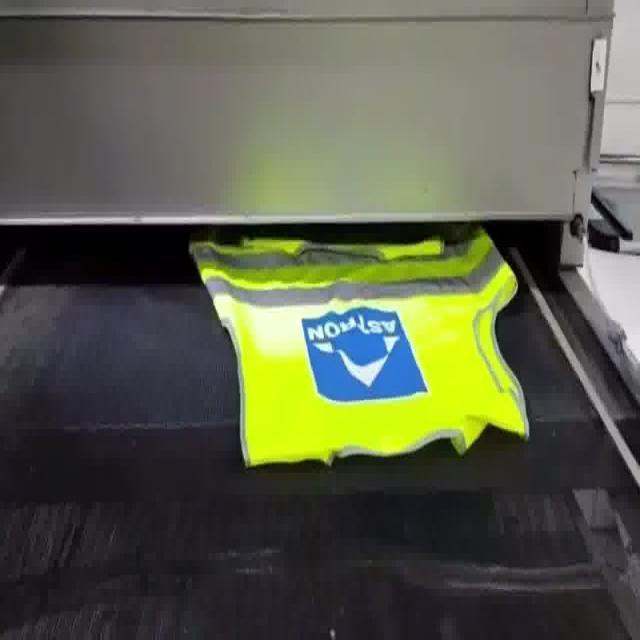

In [8]:
from IPython import display
display.Image("/content/ppe_dataset/test/images/Twalv1052_jpg.rf.7f16d8916199b8dceb712fd10eed0bf8.jpg")

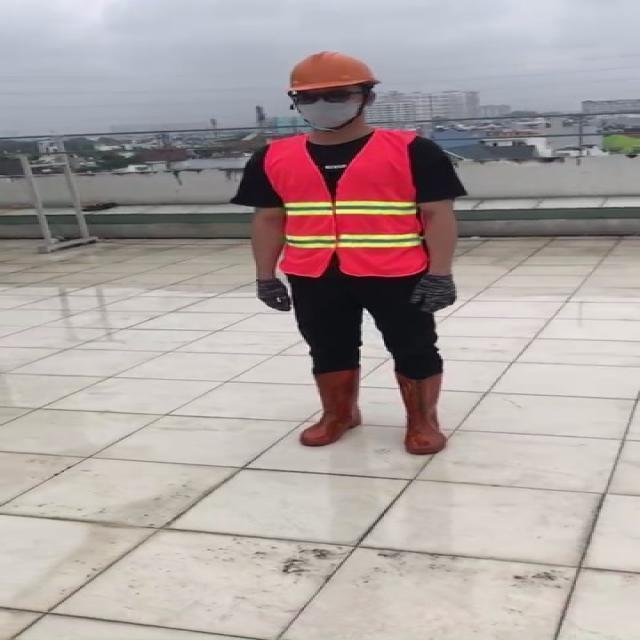

In [9]:
from PIL import Image
Image.open("/content/ppe_dataset/test/images/Video1_195_jpg.rf.2b6b4a84bc217dd4e9e23890c9e2b06c.jpg")

In [10]:
# Trained on a GPU in class; the resulting weights are loaded below as best (1).pt
# (this run was interrupted on CPU, so re-run on a Colab GPU if you want to retrain)
# model.train(data = "/content/ppe_dataset/data.yaml", epochs = 5, batch = 32)

## 3. Predict with the trained model (`best (1).pt`)

In [12]:
model_1 = YOLO("/content/best (1).pt")

In [13]:
pred=model_1.predict("/content/ppe_dataset/train/images/00014_jpg.rf.3c5cdb505af9d80d4ecde07ceedcef69.jpg", conf = 0.50)


image 1/1 /content/ppe_dataset/train/images/00014_jpg.rf.3c5cdb505af9d80d4ecde07ceedcef69.jpg: 640x640 1 no helmet, 2 vests, 818.8ms
Speed: 8.5ms preprocess, 818.8ms inference, 7.2ms postprocess per image at shape (1, 3, 640, 640)


array([[[ 24,  44,  75],
        [ 26,  46,  77],
        [ 28,  48,  83],
        ...,
        [149, 150, 160],
        [149, 149, 163],
        [139, 140, 154]],

       [[ 26,  46,  77],
        [ 28,  48,  79],
        [ 28,  49,  81],
        ...,
        [150, 151, 161],
        [151, 151, 165],
        [141, 142, 156]],

       [[ 32,  52,  83],
        [ 32,  52,  83],
        [ 30,  51,  83],
        ...,
        [151, 152, 162],
        [153, 153, 167],
        [143, 144, 158]],

       ...,

       [[147, 151, 156],
        [146, 150, 155],
        [145, 149, 154],
        ...,
        [205, 176, 162],
        [180, 151, 137],
        [161, 132, 118]],

       [[147, 151, 156],
        [146, 150, 155],
        [145, 149, 154],
        ...,
        [144, 117, 103],
        [114,  87,  73],
        [ 95,  68,  54]],

       [[146, 150, 155],
        [145, 149, 154],
        [144, 148, 153],
        ...,
        [132, 105,  91],
        [ 94,  67,  53],
        [ 70,  43,  29]]], shape=(640, 640, 3), dtype=uint8)
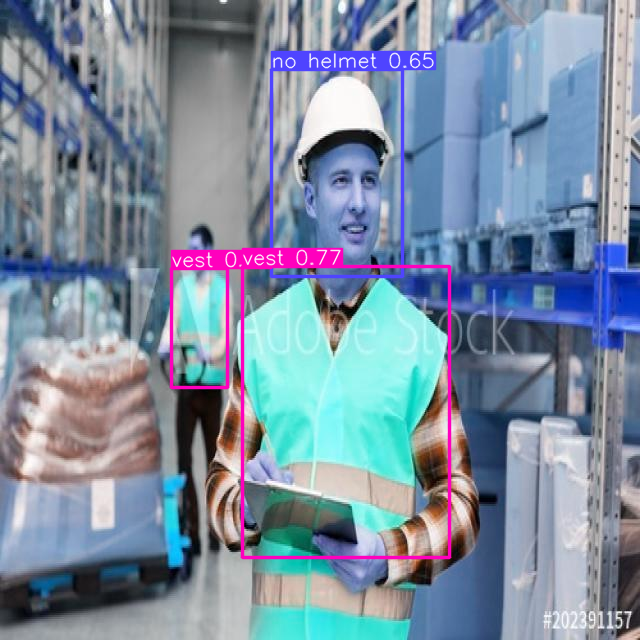

In [14]:
pred[0].plot()

In [15]:
imgh = model_1.predict("/content/ppe_dataset/valid/images/KakaoTalk_20221018_001219713_24_jpg.rf.773ae4987571777cc0a57314e94fcf9b.jpg", save = True)


image 1/1 /content/ppe_dataset/valid/images/KakaoTalk_20221018_001219713_24_jpg.rf.773ae4987571777cc0a57314e94fcf9b.jpg: 640x640 2 bootss, 1 gloves, 1 helmet, 1 helmet on, 2 persons, 1 vest, 686.8ms
Speed: 9.1ms preprocess, 686.8ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-2


array([[[214, 208, 171],
        [209, 203, 166],
        [205, 201, 166],
        ...,
        [172, 177, 175],
        [171, 176, 174],
        [171, 176, 174]],

       [[213, 207, 170],
        [208, 202, 165],
        [206, 202, 167],
        ...,
        [174, 179, 177],
        [173, 178, 176],
        [173, 178, 176]],

       [[211, 205, 168],
        [208, 202, 165],
        [207, 203, 168],
        ...,
        [176, 181, 179],
        [175, 180, 178],
        [175, 180, 178]],

       ...,

       [[128, 163, 153],
        [127, 162, 152],
        [126, 161, 151],
        ...,
        [129, 161, 166],
        [131, 163, 168],
        [132, 164, 169]],

       [[125, 160, 150],
        [124, 159, 149],
        [122, 157, 147],
        ...,
        [130, 160, 165],
        [130, 160, 165],
        [131, 161, 166]],

       [[121, 156, 146],
        [120, 155, 145],
        [119, 154, 144],
        ...,
        [130, 160, 165],
        [129, 159, 164],
        [128, 158, 163]]], shape=(640, 640, 3), dtype=uint8)
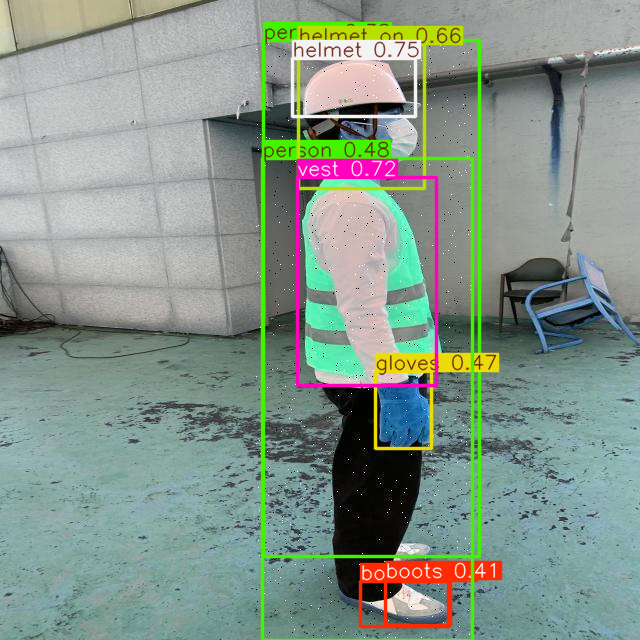

In [16]:
imgh[0].plot()

## 4. Video prediction

In [17]:
model_1.predict("/content/WhatsApp Video 2026-10-18 at 17.19.57.mp4", save = True)

In [18]:
model_1.predict("/content/WhatsApp Video 2026-10-18 at 17.20.05.mp4", save = True, conf = 0.50)

In [ ]:
display.Video("/content/runs/detect/predict/WhatsApp Video 2026-10-18 at 17.19.57.avi", embed=True)

In [21]:
import os

# Define the input and output paths for both videos
videos = [
    {
        "avi": "/content/runs/detect/predict/WhatsApp Video 2026-10-18 at 17.19.57.avi",
        "mp4": "/content/runs/detect/predict/WhatsApp_Video_Predicted.mp4"
    },
    {
        "avi": "/content/runs/detect/predict/WhatsApp Video 2026-10-18 at 17.20.05.avi",
        "mp4": "/content/runs/detect/predict/WhatsApp_Video_Predicted(1).mp4"
    }
]

# Convert each video from AVI to MP4 compatible with web browsers
for video in videos:
    avi_path = video["avi"]
    mp4_path = video["mp4"]

    if os.path.exists(avi_path):
        print(f"Converting {os.path.basename(avi_path)}...")
        os.system(f'ffmpeg -y -i "{avi_path}" -vcodec libx264 -f mp4 "{mp4_path}" > /dev/null 2>&1')

        if os.path.exists(mp4_path):
            print(f"Successfully converted to {os.path.basename(mp4_path)}!")
        else:
            print(f"Error: Conversion failed for {os.path.basename(avi_path)}.")
    else:
        print(f"Error: Source file {os.path.basename(avi_path)} not found. Make sure prediction was run.")

Converting WhatsApp Video 2026-10-18 at 17.19.57.avi...
Successfully converted to WhatsApp_Video_Predicted.mp4!
Converting WhatsApp Video 2026-10-18 at 17.20.05.avi...
Successfully converted to WhatsApp_Video_Predicted(1).mp4!


In [ ]:
from IPython import display
display.Video("/content/runs/detect/predict/WhatsApp_Video_Predicted.mp4", embed=True)

In [ ]:
display.Video("/content/runs/detect/predict/WhatsApp_Video_Predicted(1).mp4", embed=True)